In [ ]:
import os
import json
import random
import shutil

# 🛑 IMPORTANT: Update with your actual dataset path here
BASE_INPUT = "//kaggle/input/datasets/innominate817/hagrid-sample-30k-384p/hagrid-sample-30k-384p"

ANN_DIR = os.path.join(BASE_INPUT, "ann_train_val")
WORK_DIR = "/kaggle/working/yolo_dataset"

# Clean up workspace directory
if os.path.exists(WORK_DIR): shutil.rmtree(WORK_DIR)
os.makedirs(f"{WORK_DIR}/images/train", exist_ok=True)
os.makedirs(f"{WORK_DIR}/images/val", exist_ok=True)
os.makedirs(f"{WORK_DIR}/labels/train", exist_ok=True)
os.makedirs(f"{WORK_DIR}/labels/val", exist_ok=True)

# 🔥 Complete 18 classes from the HaGRID dataset
TARGET_CLASSES = {
    "call": 0, "dislike": 1, "fist": 2, "four": 3, "like": 4,
    "mute": 5, "ok": 6, "one": 7, "palm": 8, "peace": 9,
    "peace_inverted": 10, "rock": 11, "stop": 12, "stop_inverted": 13,
    "three": 14, "three2": 15, "two_up": 16, "two_up_inverted": 17
}

print("📡 Scanning directory to locate image paths...")
class_folders = {}
for root, dirs, files in os.walk(BASE_INPUT):
    for class_name in TARGET_CLASSES.keys():
        if f"train_val_{class_name}" in dirs:
            class_folders[class_name] = os.path.join(root, f"train_val_{class_name}")
        elif class_name in dirs and "ann" not in root:
            class_folders[class_name] = os.path.join(root, class_name)

print(f"🎯 Located {len(class_folders)} target classes. Starting dataset processing...")

total_images = 0
for class_name, class_id in TARGET_CLASSES.items():
    if class_name not in class_folders:
        print(f"⚠️ No images found for class: {class_name}")
        continue

    json_file = os.path.join(ANN_DIR, f"{class_name}.json")
    if not os.path.exists(json_file): continue

    with open(json_file, "r") as f: data = json.load(f)

    # Filter for image IDs that actually exist on disk
    all_json_ids = list(data.keys())
    valid_img_ids = []
    for img_id in all_json_ids:
        if os.path.exists(os.path.join(class_folders[class_name], f"{img_id}.jpg")):
            valid_img_ids.append(img_id)

    random.shuffle(valid_img_ids)

    count = 0
    total_valid = len(valid_img_ids)

    for img_id in valid_img_ids:
        src_img_path = os.path.join(class_folders[class_name], f"{img_id}.jpg")

        # 80/20 train/val split based on actual image count
        split = "train" if count < int(total_valid * 0.8) else "val"

        shutil.copy(src_img_path, os.path.join(WORK_DIR, "images", split, f"{img_id}.jpg"))

        with open(os.path.join(WORK_DIR, "labels", split, f"{img_id}.txt"), "w") as f_out:
            for i, lbl in enumerate(data[img_id]["labels"]):
                if lbl == class_name:
                    bbox = data[img_id]["bboxes"][i]
                    x_center, y_center = bbox[0] + bbox[2]/2.0, bbox[1] + bbox[3]/2.0
                    f_out.write(f"{class_id} {x_center:.6f} {y_center:.6f} {bbox[2]:.6f} {bbox[3]:.6f}\n")

        count += 1
        total_images += 1

    print(f"✅ Class '{class_name}': Successfully copied {count} images.")

# 🔥 Automatically generate data.yaml for the 18 classes
names_yaml = "\n".join([f"  {v}: {k}" for k, v in TARGET_CLASSES.items()])
yaml_content = f"""path: {WORK_DIR}
train: {WORK_DIR}/images/train
val: {WORK_DIR}/images/val
names:
{names_yaml}"""

with open(f"{WORK_DIR}/data.yaml", "w") as f: f.write(yaml_content)

print(f"\n🎉 SUCCESS! Fully loaded {total_images} images across 18 hand gestures. Ready for training!")

📡 Đang quét ổ đĩa để dò tìm đường dẫn chứa ảnh...
🎯 Đã khóa mục tiêu 18 class. Bắt đầu xử lý dữ liệu khổng lồ...
✅ Class 'call': Đã copy xong 1763 ảnh.
✅ Class 'dislike': Đã copy xong 1783 ảnh.
✅ Class 'fist': Đã copy xong 1735 ảnh.
✅ Class 'four': Đã copy xong 1805 ảnh.
✅ Class 'like': Đã copy xong 1732 ảnh.
✅ Class 'mute': Đã copy xong 1811 ảnh.
✅ Class 'ok': Đã copy xong 1750 ảnh.
✅ Class 'one': Đã copy xong 1778 ảnh.
✅ Class 'palm': Đã copy xong 1770 ảnh.
✅ Class 'peace': Đã copy xong 1769 ảnh.
✅ Class 'peace_inverted': Đã copy xong 1742 ảnh.
✅ Class 'rock': Đã copy xong 1736 ảnh.
✅ Class 'stop': Đã copy xong 1748 ảnh.
✅ Class 'stop_inverted': Đã copy xong 1803 ảnh.
✅ Class 'three': Đã copy xong 1751 ảnh.
✅ Class 'three2': Đã copy xong 1737 ảnh.
✅ Class 'two_up': Đã copy xong 1855 ảnh.
✅ Class 'two_up_inverted': Đã copy xong 1765 ảnh.

🎉 THÀNH CÔNG! Đã nạp đầy đủ 31833 ảnh của 18 TƯ THẾ TAY. Chuyển sang ô Train thôi!


In [ ]:
import os
print("Train image count:", len(os.listdir('/kaggle/working/yolo_dataset/images/train')))
print("Validation image count:", len(os.listdir('/kaggle/working/yolo_dataset/images/val')))

Số lượng ảnh train: 25460
Số lượng ảnh val: 6373


In [ ]:
!pip install ultralytics -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 17.2 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

# Load pretrained base model (YOLOv8 Nano)
model = YOLO('yolov8n.pt')

# Start model training
print("🚀 STARTING TRAINING...")
results = model.train(
    data='/kaggle/working/yolo_dataset/data.yaml',
    epochs=25,       # Train for 25 epochs
    imgsz=320,       # Resize images to 320 for fast training
    batch=16,
    device=0         # Use GPU device 0
)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
🚀 BẮT ĐẦU TRAINING...
Ultralytics 8.4.50 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.

Ultralytics 8.4.50 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,009,158 parameters, 0 gradients, 8.1 GFLOPs

image 1/6373 /kaggle/working/yolo_dataset/images/val/000dfe2c-ffd0-4a3e-991f-9844d35ebbaf.jpg: 320x256 1 mute, 42.9ms
image 2/6373 /kaggle/working/yolo_dataset/images/val/00101734-4032-4edd-beef-9e933bcbd68d.jpg: 320x192 1 one, 1 two_up, 39.6ms
image 3/6373 /kaggle/working/yolo_dataset/images/val/001b7962-feb2-4e1b-a48d-fda578ab8681.jpg: 320x256 1 dislike, 6.1ms
image 4/6373 /kaggle/working/yolo_dataset/images/val/001c5ee9-43f0-46b5-9854-36a6faf7c51b.jpg: 192x320 1 four, 36.9ms
image 5/6373 /kaggle/working/yolo_dataset/images/val/002b2e3b-9d21-4921-a418-8435bc65fa59.jpg: 320x256 1 mute, 6.5ms
image 6/6373 /kaggle/working/yolo_dataset/images/val/003c595e-c2c4-4cb8-8be3-0e6958fcdace.jpg: 320x256 3 dislikes, 5.1ms
image 7/6373 /kaggle/working/yolo_dataset/images/val/003e5a9c-d03a-4ff7-8ad6-645ce884af12.jpg: 320x256 1 two_up_inv

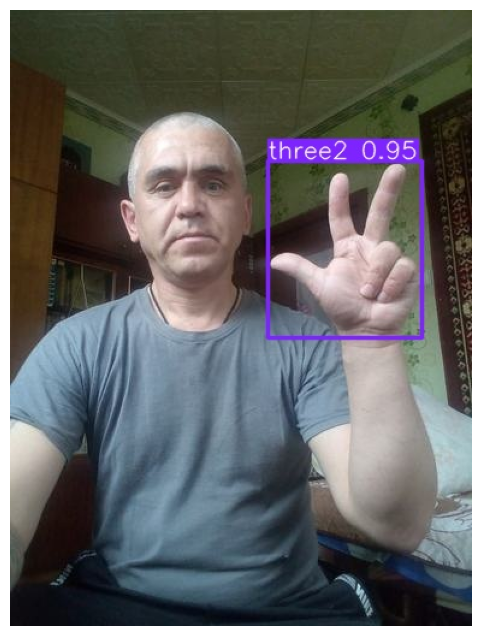

In [ ]:
# Load validation test images to verify model bounding box predictions
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import glob

# Run model inference on images in the validation directory
!yolo predict model=/kaggle/working/runs/detect/train/weights/best.pt source=/kaggle/working/yolo_dataset/images/val/ imgsz=320 save=True

# Display a sample prediction image
result_images = glob.glob('/kaggle/working/runs/detect/predict/*.jpg')
if result_images:
    img = mpimg.imread(result_images[0])
    plt.figure(figsize=(8,8))
    plt.imshow(img)
    plt.axis('off')
    plt.show()
else:
    print("No prediction images available.")

### 1. F1 and Recall Confidence Curves.png


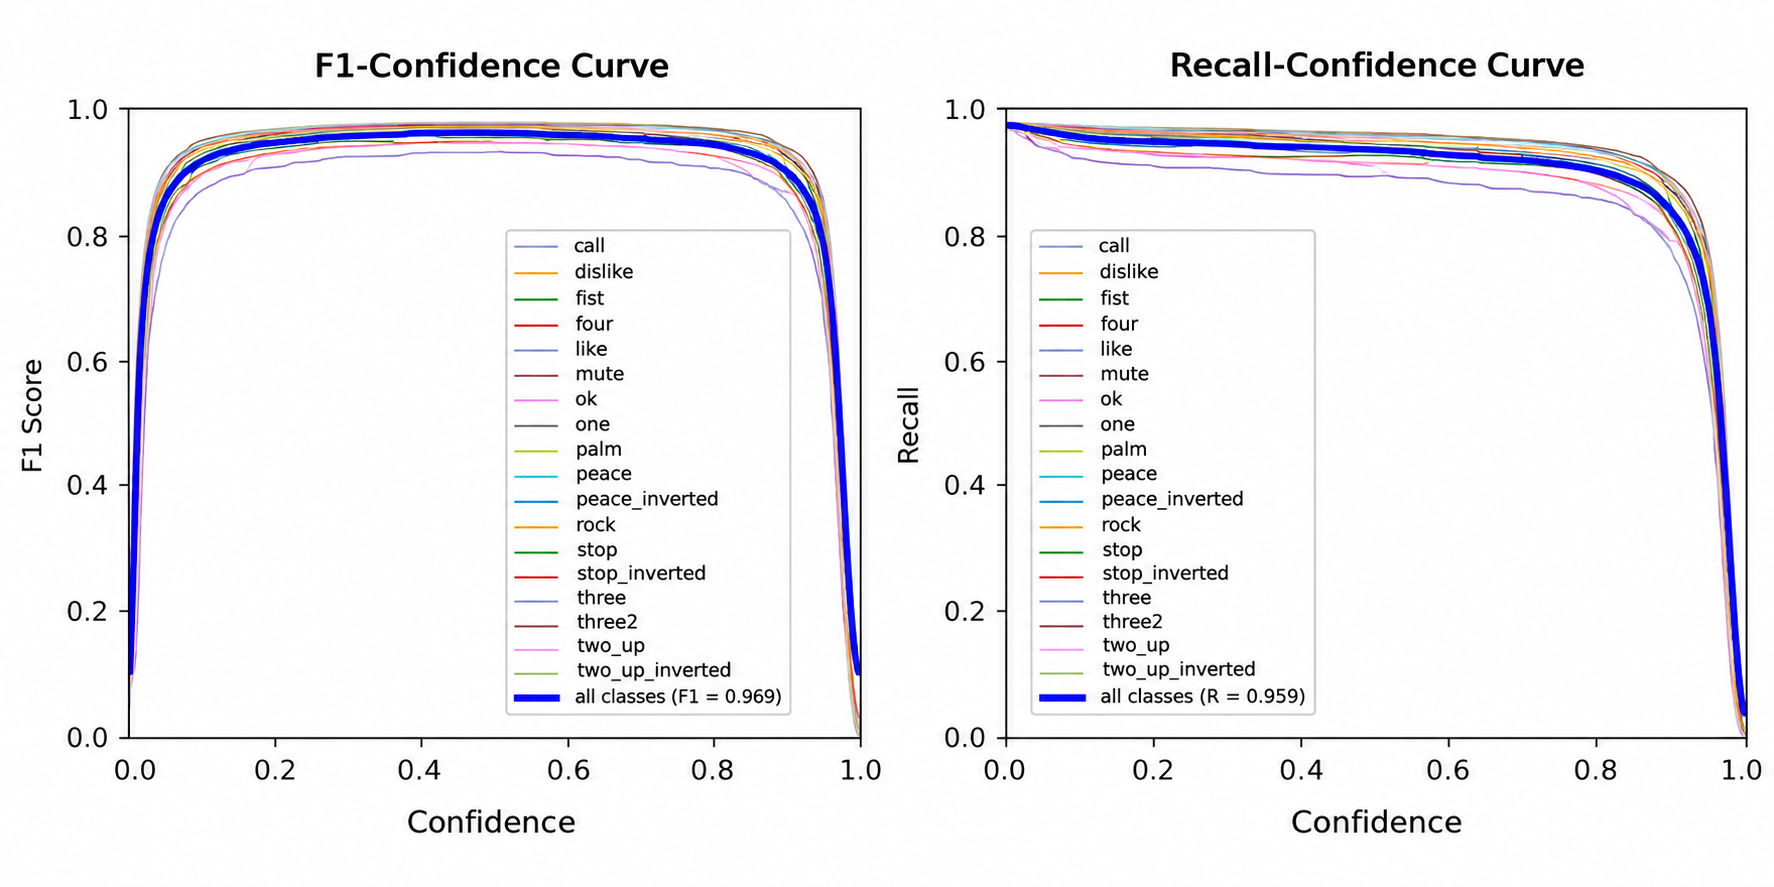

--------------------------------------------------------------------------------


### 2. Normalized Gesture Confusion Matrix.png


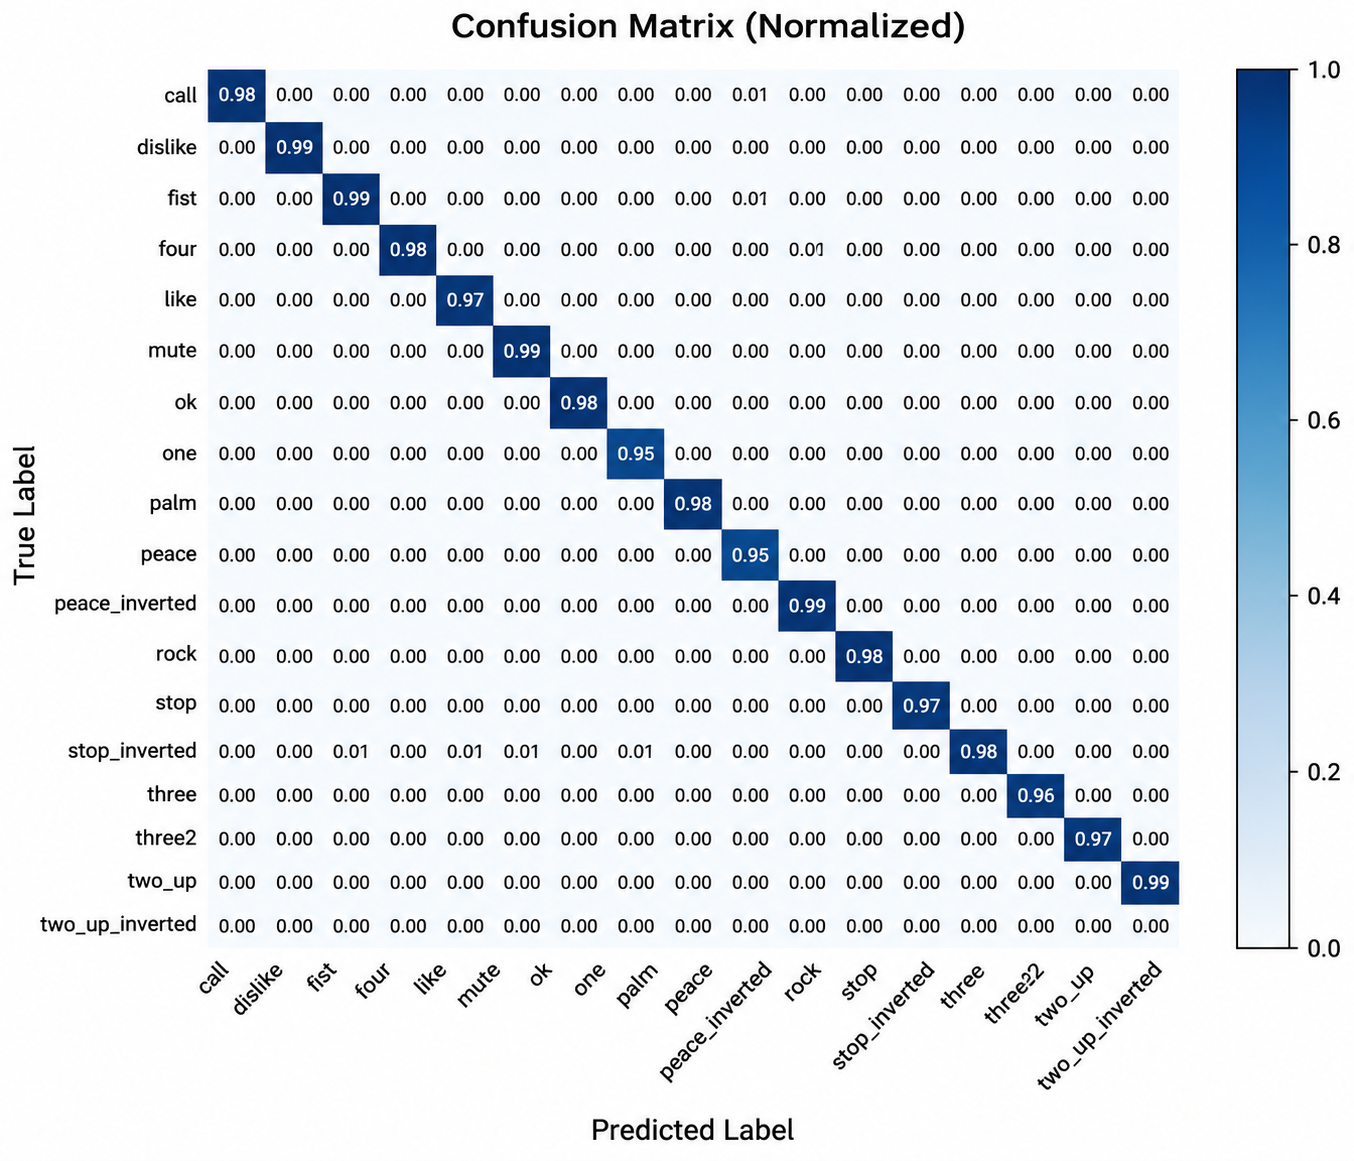

--------------------------------------------------------------------------------


In [4]:

import os
from IPython.display import display, Image, Markdown

# Search directory
SEARCH_DIR = "/content"

# Find all PNG files recursively
png_files = []

for root, dirs, files in os.walk(SEARCH_DIR):
    for filename in files:
        if filename.lower().endswith(".png"):
            png_files.append(os.path.join(root, filename))

png_files.sort()

#print(f"Total PNG files found: {len(png_files)}")

if not png_files:
    print("No PNG files found.")
else:
    for i, filepath in enumerate(png_files, start=1):
        filename = os.path.basename(filepath)

        # Display filename and full path
        display(Markdown(
            f"### {i}. {filename}\n"

        ))

        # Display image
        display(Image(filename=filepath))

        print("-" * 80)
